In [11]:
import glob
import open3d as o3d
import cv2
import matplotlib.pyplot as plt
import numpy as np
from Final_Functions import load_and_undistort_images, CalibrateStereoCamera, robot_masking_MOG2
calibration = np.load("calibration_maps.npz")
Q = calibration["Q"]
fps=30

# Stereo disparity experiments

Run the cells in order from the project directory. The first four experiments use one rectified stereo pair from `1_no_obstacle`. Steps 5 and 6 use a sample of the sequence to estimate the static background and fit the back wall and floor. Step 7 combines those results into a cleaned, colored point cloud.

In [12]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from sklearn.linear_model import RANSACRegressor

if not hasattr(cv2, "ximgproc"):
    raise ImportError("SGBM's WLS filter requires OpenCV with the contrib modules.")

scene_folder = Path("1_no_obstacle")
left_paths = sorted((scene_folder / "left").glob("*.png"))
right_paths = sorted((scene_folder / "right").glob("*.png"))
if not left_paths or [path.name for path in left_paths] != [path.name for path in right_paths]:
    raise ValueError(f"Expected matching left and right PNG filenames in {scene_folder}.")

with np.load("calibration_maps.npz") as calibration:
    left_remap = (calibration["mapLx"], calibration["mapLy"])
    right_remap = (calibration["mapRx"], calibration["mapRy"])
    Q = calibration["Q"]


def read_rectified_pair(index):
    gray_images = []
    for path, remap in ((left_paths[index], left_remap), (right_paths[index], right_remap)):
        image = cv2.imread(str(path))
        if image is None:
            raise OSError(f"Could not read {path}")
        rectified = cv2.remap(image, *remap, interpolation=cv2.INTER_LINEAR)
        gray_images.append(cv2.cvtColor(rectified, cv2.COLOR_BGR2GRAY))
    return tuple(gray_images)

In [13]:
def create_experiment_matchers(min_disparity=0, num_disparities=5 * 16, block_size=5):
    left_matcher = cv2.StereoSGBM_create(
        minDisparity=min_disparity,
        numDisparities=num_disparities,
        blockSize=block_size,
        P1=8 * block_size**2,
        P2=32 * block_size**2,
        disp12MaxDiff=1,
        preFilterCap=31,
        uniquenessRatio=20,
        speckleWindowSize=80,
        speckleRange=2,
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
    )
    wls = cv2.ximgproc.createDisparityWLSFilter(left_matcher)
    wls.setLambda(2000)
    wls.setSigmaColor(0.8)
    return left_matcher, cv2.ximgproc.createRightMatcher(left_matcher), wls


def disparity_in_pixels(fixed_point_map, min_disparity):
    disparity = fixed_point_map.astype(np.float32) / 16.0
    disparity[disparity < min_disparity] = np.nan
    return disparity


def calculate_experiment_disparity(
    left_matcher, right_matcher, wls, left_image_gray, right_image_gray,
    test=False, crop=0.0, clahe=None,
):
    """Return WLS disparity, plus raw disparity and confidence if test is True."""
    if not 0 <= crop < 1:
        raise ValueError("crop must be between 0 and 1")
    first_row = int(left_image_gray.shape[0] * crop)
    guide = left_image_gray[first_row:, :]
    left_gray, right_gray = guide, right_image_gray[first_row:, :]
    if clahe is not None:
        left_gray, right_gray = clahe.apply(left_gray), clahe.apply(right_gray)

    left_fixed = left_matcher.compute(left_gray, right_gray)
    right_fixed = right_matcher.compute(right_gray, left_gray)
    filtered_fixed = wls.filter(left_fixed, guide, None, right_fixed)
    min_disparity = left_matcher.getMinDisparity()
    padding = ((first_row, 0), (0, 0))

    filtered = disparity_in_pixels(filtered_fixed, min_disparity)
    if first_row:
        filtered = np.pad(filtered, padding, constant_values=np.nan)
    if not test:
        return filtered

    raw = disparity_in_pixels(left_fixed, min_disparity)
    confidence = wls.getConfidenceMap().copy()
    if first_row:
        raw = np.pad(raw, padding, constant_values=np.nan)
        confidence = np.pad(confidence, padding, constant_values=0)
    return filtered, raw, confidence

In [14]:
display_max_disparity = 45  # Pixels, shared by all disparity plots
disparity_cmap = plt.get_cmap("viridis").with_extremes(bad="#e5e7eb")


def show_disparities(maps):
    fig, axes = plt.subplots(1, len(maps), figsize=(11, 4), layout="constrained")
    for ax, (title, disparity) in zip(axes, maps.items()):
        image = ax.imshow(disparity, cmap=disparity_cmap, vmin=0, vmax=display_max_disparity)
        ax.set_title(title)
        ax.axis("off")
    fig.colorbar(image, ax=axes, label="Disparity (px)")
    plt.show()


def print_coverage(maps):
    for label, disparity in maps.items():
        print(f"{label} coverage {np.isfinite(disparity).mean():.1%}")

## 1. Compare raw SGBM and WLS

Start with a 5-pixel block and the full rectified frame. Invalid disparities are shown in light gray. Coverage is the fraction of the full frame with finite disparity.

Stereo pair 000000.png
Raw SGBM coverage 93.8%
WLS-filtered coverage 93.7%


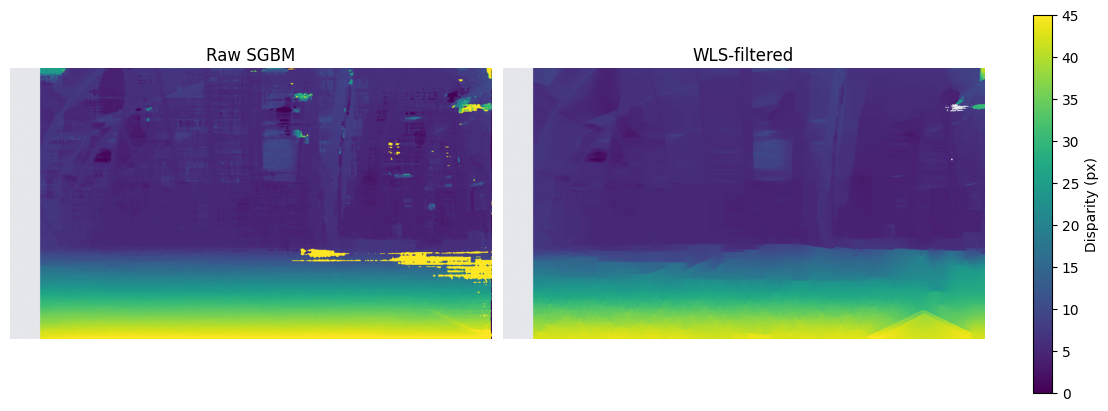

In [15]:
comparison_frame = 0
left_gray, right_gray = read_rectified_pair(comparison_frame)
matchers_5 = create_experiment_matchers(block_size=5)
wls_5, raw_5, confidence_5 = calculate_experiment_disparity(
    *matchers_5, left_gray, right_gray, test=True,
)

raw_and_wls = {"Raw SGBM": raw_5, "WLS-filtered": wls_5}
print(f"Stereo pair {left_paths[comparison_frame].name}")
print_coverage(raw_and_wls)
show_disparities(raw_and_wls)

## 2. Filter by WLS confidence

WLS scores range from 0 to 255. Start with a threshold of 128 and mark low-confidence pixels as invalid.

Confidence ≥ 128 coverage 85.0%


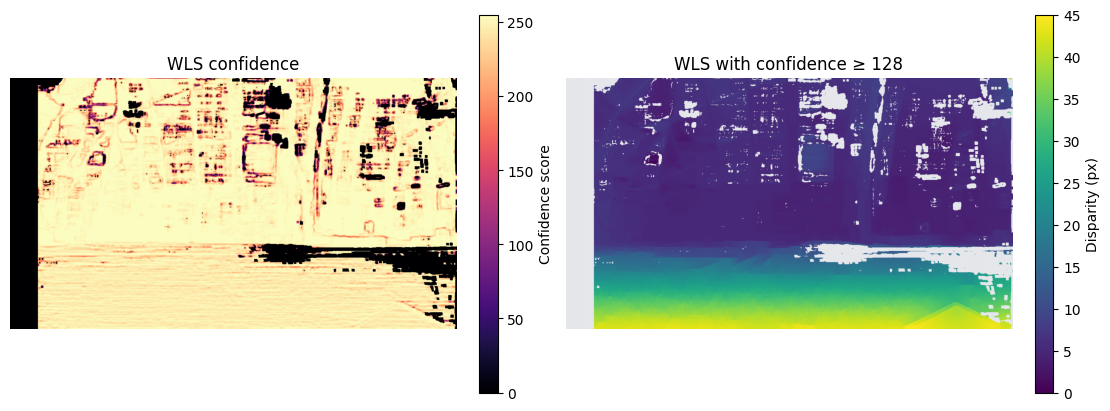

In [16]:
confidence_threshold = 128


def filter_by_confidence(disparity, confidence, threshold):
    return np.where(confidence >= threshold, disparity, np.nan)


confident_5 = filter_by_confidence(wls_5, confidence_5, confidence_threshold)
print_coverage({f"Confidence ≥ {confidence_threshold}": confident_5})

fig, (ax_confidence, ax_disparity) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
confidence_image = ax_confidence.imshow(confidence_5, cmap="magma", vmin=0, vmax=255)
disparity_image = ax_disparity.imshow(confident_5, cmap=disparity_cmap, vmin=0, vmax=display_max_disparity)
ax_confidence.set_title("WLS confidence")
ax_disparity.set_title(f"WLS with confidence ≥ {confidence_threshold}")
ax_confidence.axis("off")
ax_disparity.axis("off")
fig.colorbar(confidence_image, ax=ax_confidence, label="Confidence score")
fig.colorbar(disparity_image, ax=ax_disparity, label="Disparity (px)")
plt.show()

## 3. Increase block size from 5 to 15

Use the same images and confidence threshold. The SGBM smoothness penalties scale with the block area.

Block size 5 coverage 85.0%
Block size 15 coverage 87.7%


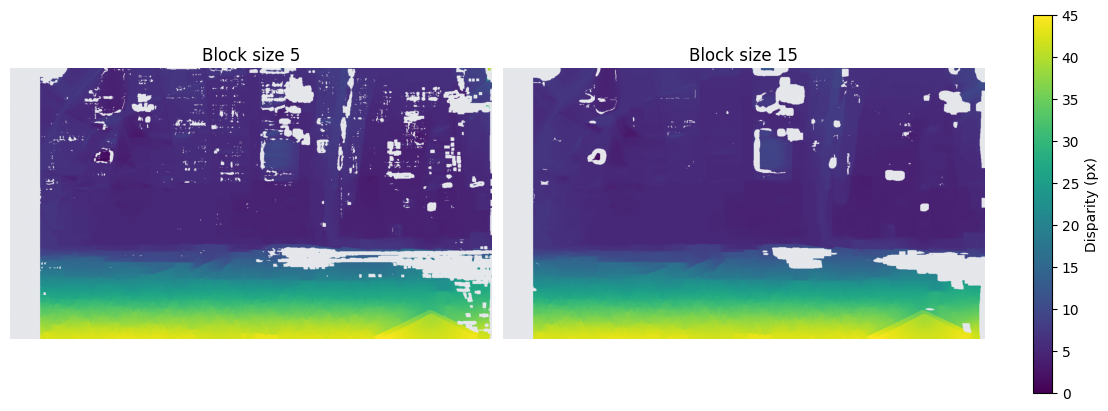

In [17]:
matchers_15 = create_experiment_matchers(block_size=15)
wls_15, _, confidence_15 = calculate_experiment_disparity(
    *matchers_15, left_gray, right_gray, test=True,
)
confident_15 = filter_by_confidence(wls_15, confidence_15, confidence_threshold)

block_comparison = {"Block size 5": confident_5, "Block size 15": confident_15}
print_coverage(block_comparison)
show_disparities(block_comparison)

## 4. Apply CLAHE to both grayscale images

Enhance both rectified grayscale images before matching. Use the original left grayscale image as the WLS guide in both runs to isolate the change to stereo matching.

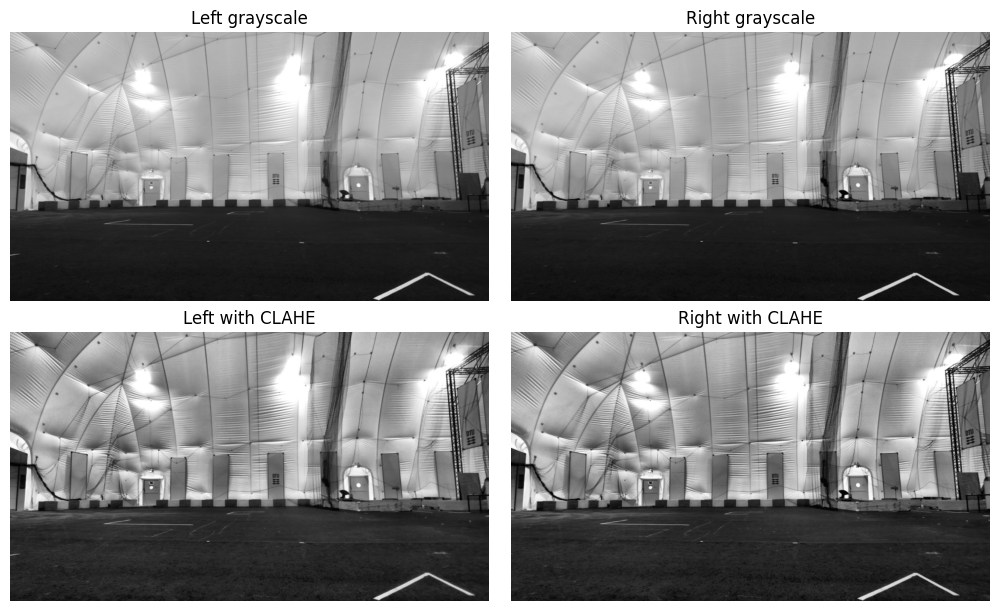

Block 15 coverage 87.7%
Block 15 with CLAHE coverage 88.1%


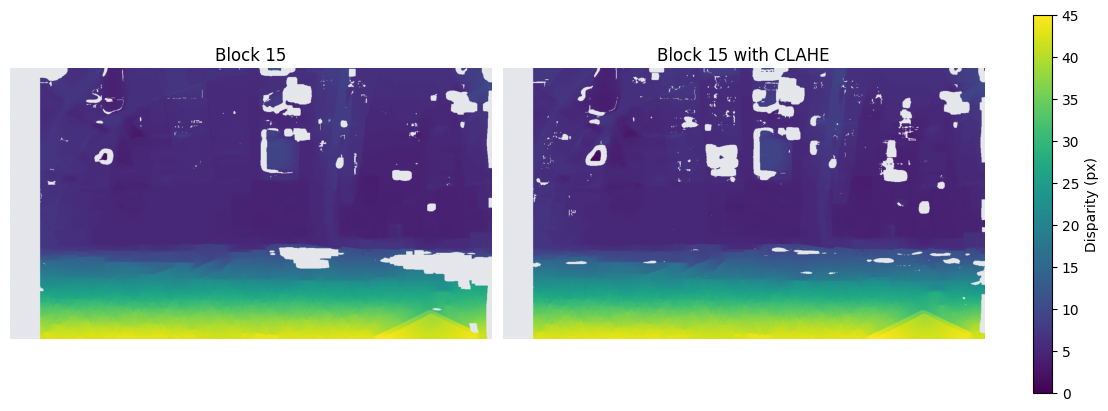

In [18]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
wls_15_clahe, _, confidence_15_clahe = calculate_experiment_disparity(
    *matchers_15, left_gray, right_gray, test=True, clahe=clahe,
)
confident_15_clahe = filter_by_confidence(wls_15_clahe, confidence_15_clahe, confidence_threshold)

fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for ax, title, gray in zip(
    axes.flat,
    ("Left grayscale", "Right grayscale", "Left with CLAHE", "Right with CLAHE"),
    (left_gray, right_gray, clahe.apply(left_gray), clahe.apply(right_gray)),
):
    ax.imshow(gray, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

clahe_comparison = {"Block 15": confident_15, "Block 15 with CLAHE": confident_15_clahe}
print_coverage(clahe_comparison)
show_disparities(clahe_comparison)

## 5. Construct the median background disparity

Sample up to 24 evenly spaced pairs from the fixed-camera sequence. Use block size 15, WLS, and the same confidence threshold. The CLAHE setting below carries forward the preprocessing from step 4. Keep a pixel's median when it has valid disparity in at least half the sampled frames.

24 sampled pairs, requiring 12 valid observations per pixel
Median background coverage 89.3%


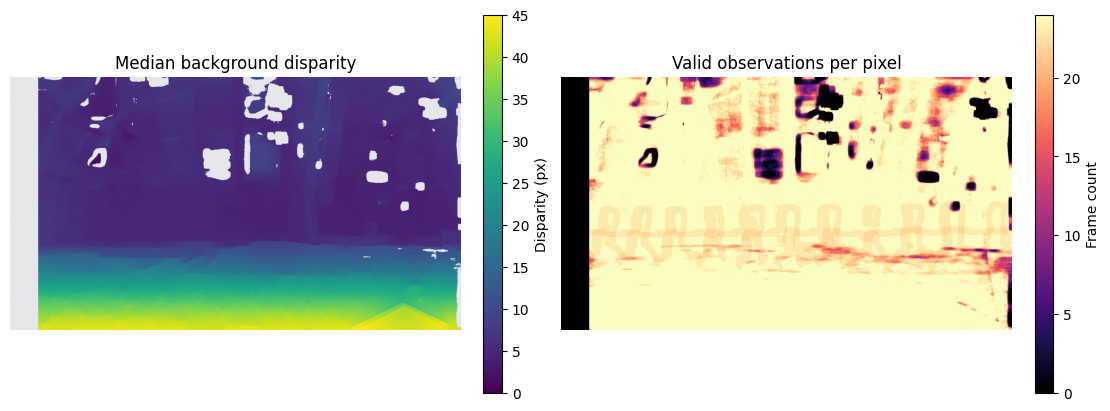

In [19]:
background_frame_count = 24
background_use_clahe = True
background_indices = np.linspace(
    0, len(left_paths) - 1, min(background_frame_count, len(left_paths)), dtype=int,
)
minimum_support = (len(background_indices) + 1) // 2


def median_background(frame_indices, matchers, threshold, min_support, clahe=None):
    disparities = []
    for frame_index in frame_indices:
        filtered, _, confidence = calculate_experiment_disparity(
            *matchers, *read_rectified_pair(frame_index), test=True, clahe=clahe,
        )
        disparities.append(filter_by_confidence(filtered, confidence, threshold))

    stack = np.stack(disparities)
    support = np.count_nonzero(np.isfinite(stack), axis=0)
    supported = support >= min_support
    background = np.full(stack.shape[1:], np.nan, dtype=np.float32)
    background[supported] = np.nanmedian(stack[:, supported], axis=0)
    return background, support


background_disparity, background_support = median_background(
    background_indices, matchers_15, confidence_threshold, minimum_support,
    clahe=clahe if background_use_clahe else None,
)
print(f"{len(background_indices)} sampled pairs, requiring {minimum_support} valid observations per pixel")
print_coverage({"Median background": background_disparity})

fig, (ax_background, ax_support) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
background_image = ax_background.imshow(
    background_disparity, cmap=disparity_cmap, vmin=0, vmax=display_max_disparity,
)
support_image = ax_support.imshow(background_support, cmap="magma", vmin=0, vmax=len(background_indices))
ax_background.set_title("Median background disparity")
ax_support.set_title("Valid observations per pixel")
ax_background.axis("off")
ax_support.axis("off")
fig.colorbar(background_image, ax=ax_background, label="Disparity (px)")
fig.colorbar(support_image, ax=ax_support, label="Frame count")
plt.show()

## 6. Fit the wall and floor with RANSAC

Fit each surface to the median background in a region selected from the rectified image. The wall region covers a central section of the back wall below the curved roof. The floor region starts below the wall–floor boundary.

A 3D plane projects to an affine disparity model `d = a*u + b*v + c` in rectified stereo. RANSAC measures residuals in disparity pixels. The calibration matrix `Q` converts each fit to a camera-frame plane `n_x*X + n_y*Y + n_z*Z + D = 0`, with a unit normal and `D` in millimeters.

Wall 53,673/55,104 inliers (97.4%), median inlier residual 0.15 px
  Disparity coefficients (a, b, c) [-1.3000e-03 -1.0000e-03  5.9114e+00]
  Camera plane (nx, ny, nz, D in mm) [-1.7500000e-01 -1.4300000e-01  9.7400000e-01 -1.0378855e+04]
Floor 106,802/145,676 inliers (73.3%), median inlier residual 0.29 px
  Disparity coefficients (a, b, c) [-1.00000e-04  1.50800e-01 -6.36787e+01]
  Camera plane (nx, ny, nz, D in mm) [-1.00000e-03  9.99000e-01 -4.60000e-02 -5.01038e+02]


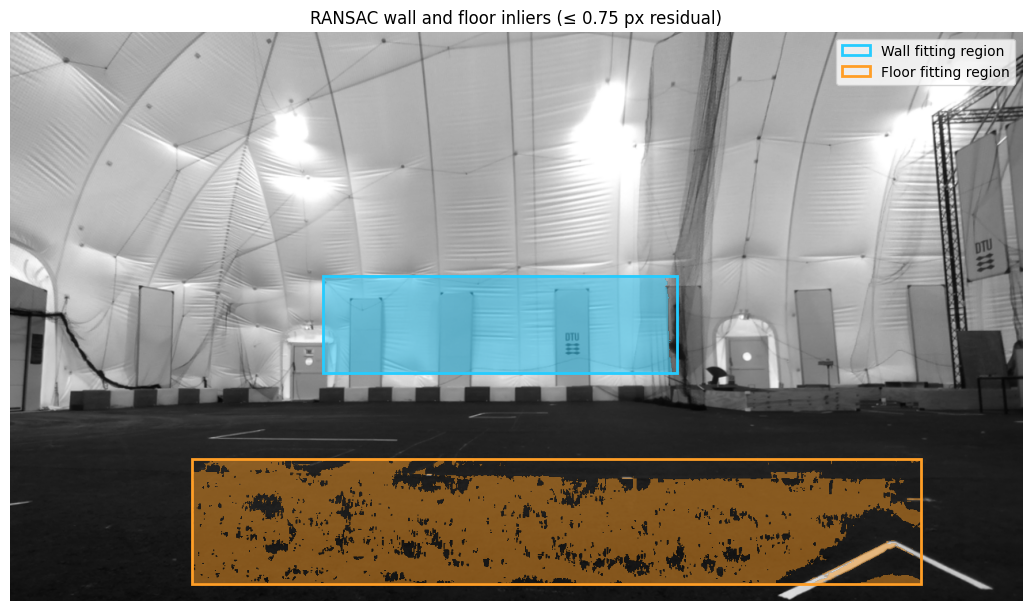

In [20]:
# Regions are fractions of the image in (left, top, right, bottom) order.
surface_regions = {
    "Wall": (0.31, 0.43, 0.66, 0.60),
    "Floor": (0.18, 0.75, 0.90, 0.97),
}
ransac_threshold = 0.75  # Absolute disparity residual in pixels
fit_stride = 3  # Fit on a regular grid, then score all valid pixels in each region


def fit_disparity_plane(disparity, region, reprojection_matrix, threshold, stride):
    height, width = disparity.shape
    left, top, right, bottom = (int(fraction * size) for fraction, size in zip(
        region, (width, height, width, height),
    ))
    region_disparity = disparity[top:bottom, left:right]
    rows, cols = np.nonzero(np.isfinite(region_disparity) & (region_disparity > 0))
    coordinates = np.column_stack((cols + left, rows + top))
    observed = region_disparity[rows, cols]
    sample = (rows % stride == 0) & (cols % stride == 0)
    if np.count_nonzero(sample) < 3:
        raise ValueError(f"Too few valid background disparities in region {region}.")

    model = RANSACRegressor(min_samples=3, residual_threshold=threshold, random_state=0)
    model.fit(coordinates[sample], observed[sample])
    a, b = model.estimator_.coef_
    c = model.estimator_.intercept_
    camera_plane = np.linalg.solve(reprojection_matrix.T, [a, b, -1, c])
    camera_plane /= np.linalg.norm(camera_plane[:3])

    residuals = np.abs(observed - model.predict(coordinates))
    inliers = residuals <= threshold
    inlier_mask = np.zeros_like(disparity, dtype=bool)
    inlier_mask[rows[inliers] + top, cols[inliers] + left] = True
    return {
        "region": (left, top, right, bottom),
        "disparity_plane": np.array([a, b, c]),
        "camera_plane": camera_plane,
        "inlier_mask": inlier_mask,
        "valid_count": observed.size,
        "median_inlier_residual": np.median(residuals[inliers]) if inliers.any() else np.nan,
    }


surface_fits = {
    name: fit_disparity_plane(background_disparity, region, Q, ransac_threshold, fit_stride)
    for name, region in surface_regions.items()
}
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
ax.imshow(left_gray, cmap="gray", vmin=0, vmax=255)
overlay = np.zeros((*background_disparity.shape, 4), dtype=np.float32)

for (name, fit), color in zip(surface_fits.items(), ((0.15, 0.8, 1), (1, 0.62, 0.15))):
    left, top, right, bottom = fit["region"]
    inliers = fit["inlier_mask"]
    overlay[inliers] = (*color, 0.48)
    ax.add_patch(Rectangle(
        (left - 0.5, top - 0.5), right - left, bottom - top,
        fill=False, edgecolor=color, linewidth=2, label=f"{name} fitting region",
    ))
    count = np.count_nonzero(inliers)
    total = fit["valid_count"]
    error = fit["median_inlier_residual"]
    print(f"{name} {count:,}/{total:,} inliers ({count / total:.1%}), median inlier residual {error:.2f} px")
    print("  Disparity coefficients (a, b, c)", np.round(fit["disparity_plane"], 4))
    print("  Camera plane (nx, ny, nz, D in mm)", np.round(fit["camera_plane"], 3))

ax.imshow(overlay)
ax.set_title(f"RANSAC wall and floor inliers (≤ {ransac_threshold:g} px residual)")
ax.legend(loc="upper right")
ax.axis("off")
plt.show()

## Recommended disparity functions for `Nicolai.ipynb`

The next cell is self-contained. Copy it in place of the stereo matcher definition and both versions of `calculate_disparity_map` in `Nicolai.ipynb`. The pipeline can call the same functions with the same arguments. The defaults are a 15-pixel block and WLS, with full-image alignment for the scene crop and the per-frame robot masks.

Block size 15 retained more confident pixels than size 5 in the sampled pairs. CLAHE's effect varied across full frames, and a confidence threshold of 128 removed about 19% of the disparity pixels eligible for robot reprojection in the sampled MOG2 masks. For static-scene disparity, try both options together by passing `clahe=cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` and `confidence_threshold=128`. Reuse the CLAHE object across frames if processing a sequence. The median background and RANSAC fits are available in steps 5 and 6 for static-scene analysis.

In [21]:
import cv2
import numpy as np


def create_stereo_matchers(min_disparity=0, num_disparities=5 * 16, block_size=15):
    """Build the left matcher, right matcher, and WLS filter."""
    left_matcher = cv2.StereoSGBM_create(
        minDisparity=min_disparity,
        numDisparities=num_disparities,
        blockSize=block_size,
        P1=8 * block_size**2,
        P2=32 * block_size**2,
        disp12MaxDiff=1,
        preFilterCap=31,
        uniquenessRatio=20,
        speckleWindowSize=80,
        speckleRange=2,
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
    )
    wls = cv2.ximgproc.createDisparityWLSFilter(left_matcher)
    wls.setLambda(2000)
    wls.setSigmaColor(0.8)
    return left_matcher, cv2.ximgproc.createRightMatcher(left_matcher), wls


def calculate_disparity_map(
    left_matcher, right_matcher, wls, left_image_gray, right_image_gray,
    test=False, crop=0.0, *, clahe=None, confidence_threshold=None,
):
    """Return image-aligned float32 WLS disparity in pixels.

    Cropped and invalid pixels are NaN. Pass an OpenCV CLAHE object to enhance
    both matching inputs or a confidence threshold from 0 to 255 to mask WLS
    pixels. With test=True, also return raw SGBM disparity and WLS confidence
    in the existing (filtered, raw, confidence) order.
    """
    if not 0 <= crop < 1:
        raise ValueError("crop must be between 0 and 1")
    if confidence_threshold is not None and not 0 <= confidence_threshold <= 255:
        raise ValueError("confidence_threshold must be between 0 and 255")

    first_row = int(left_image_gray.shape[0] * crop)
    guide = left_image_gray[first_row:, :]
    left_gray = guide
    right_gray = right_image_gray[first_row:, :]
    if clahe is not None:
        left_gray = clahe.apply(left_gray)
        right_gray = clahe.apply(right_gray)

    left_fixed = left_matcher.compute(left_gray, right_gray)
    right_fixed = right_matcher.compute(right_gray, left_gray)
    filtered = wls.filter(left_fixed, guide, None, right_fixed).astype(np.float32) / 16.0
    filtered[filtered < left_matcher.getMinDisparity()] = np.nan

    if test or confidence_threshold is not None:
        confidence = wls.getConfidenceMap()
    if confidence_threshold is not None:
        filtered[~(confidence >= confidence_threshold)] = np.nan

    padding = ((first_row, 0), (0, 0))
    if first_row:
        filtered = np.pad(filtered, padding, constant_values=np.nan)
    if not test:
        return filtered

    # Keep the SGBM invalid value in the computed area for existing debug callers.
    raw = left_fixed.astype(np.float32) / 16.0
    if first_row:
        raw = np.pad(raw, padding, constant_values=np.nan)
        confidence = np.pad(confidence, padding, constant_values=0)
    else:
        confidence = confidence.copy()
    return filtered, raw, confidence

## 7. Clean static-scene point cloud

Use the confidence-filtered median from step 5. It combines 15-pixel SGBM, CLAHE on both grayscale images, WLS, and temporal support across the fixed-camera sequence. For the wall and floor inliers from step 6, evaluate the fitted disparity at the original pixel so each refined point stays on its camera ray. Keep the measured median elsewhere.

Reproject with the full-frame calibration, add RGB from the first sampled rectified left image, and keep finite points in front of the camera with disparity above 3 px. A 5 cm voxel grid reduces oversampling, and the 20-neighbor statistical filter removes isolated points. The result is `clean_scene_pcd`, an Open3D cloud in calibration millimeters. The inline views use meters. In a desktop session, `o3d.visualization.draw_geometries([clean_scene_pcd])` opens a rotatable view.

In [22]:
min_cloud_disparity = 3.0  # Pixels
cloud_voxel_size_mm = 50.0

refined_background_disparity = background_disparity.copy()
plane_point_counts = {}
for name, fit in surface_fits.items():
    rows, cols = np.nonzero(fit["inlier_mask"])
    a, b, c = fit["disparity_plane"]
    refined_background_disparity[rows, cols] = a * cols + b * rows + c
    plane_point_counts[name] = len(rows)

reference_index = background_indices[0]
reference_path = left_paths[reference_index]
reference_bgr = cv2.imread(str(reference_path))
if reference_bgr is None:
    raise OSError(f"Could not read {reference_path}")
reference_bgr = cv2.remap(reference_bgr, *left_remap, interpolation=cv2.INTER_LINEAR)
reference_rgb = cv2.cvtColor(reference_bgr, cv2.COLOR_BGR2RGB)

scene_xyz_mm = cv2.reprojectImageTo3D(refined_background_disparity, Q)
valid_points = (
    np.isfinite(refined_background_disparity)
    & (refined_background_disparity > min_cloud_disparity)
    & np.isfinite(scene_xyz_mm).all(axis=2)
    & (scene_xyz_mm[..., 2] > 0)
)
if not valid_points.any():
    raise ValueError("No valid background points to reconstruct.")

background_pcd = o3d.geometry.PointCloud()
background_pcd.points = o3d.utility.Vector3dVector(scene_xyz_mm[valid_points])
background_pcd.colors = o3d.utility.Vector3dVector(reference_rgb[valid_points] / 255.0)

voxel_pcd = background_pcd.voxel_down_sample(cloud_voxel_size_mm)
clean_scene_pcd, _ = voxel_pcd.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)

print(f"Plane-refined pixels: {plane_point_counts['Wall']:,} wall, {plane_point_counts['Floor']:,} floor")
print(f"Point counts: {len(background_pcd.points):,} reprojected, "
      f"{len(voxel_pcd.points):,} voxelized, {len(clean_scene_pcd.points):,} after outlier removal")

Plane-refined pixels: 53,673 wall, 106,802 floor
Point counts: 821,871 reprojected, 125,499 voxelized, 122,071 after outlier removal


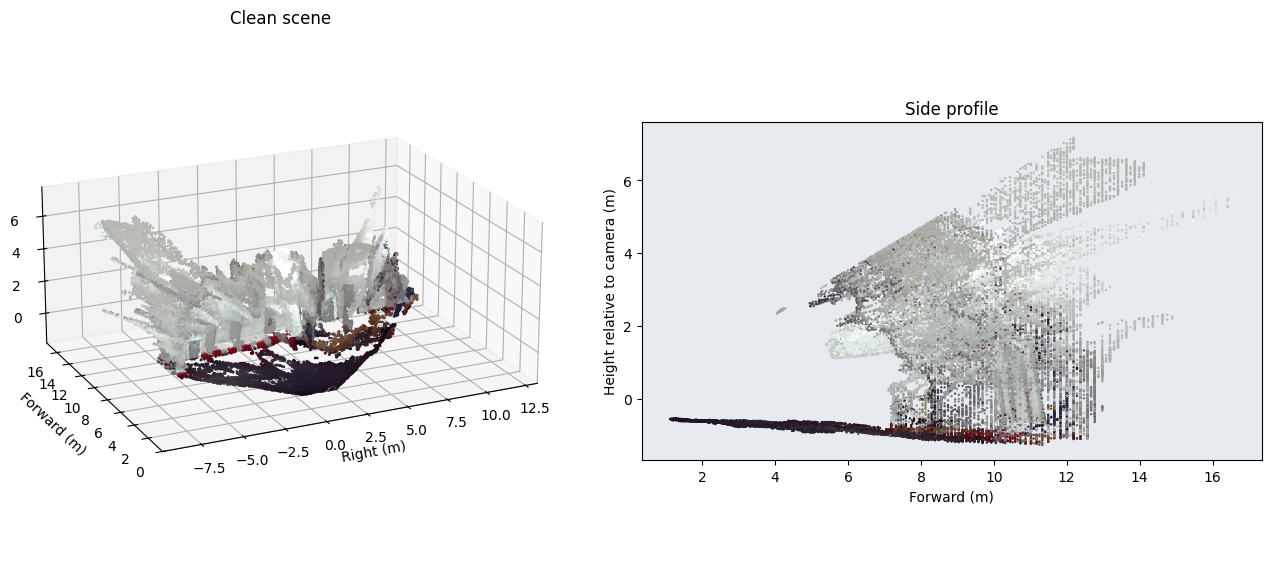

In [23]:
cloud_points_mm = np.asarray(clean_scene_pcd.points)
cloud_colors = np.asarray(clean_scene_pcd.colors)
if not len(cloud_points_mm):
    raise ValueError("The spatial filters removed every point.")

preview_indices = np.random.default_rng(0).choice(
    len(cloud_points_mm), size=min(50_000, len(cloud_points_mm)), replace=False,
)
right_m, down_m, forward_m = (cloud_points_mm[preview_indices] / 1_000).T
height_m = -down_m
preview_colors = cloud_colors[preview_indices]

fig = plt.figure(figsize=(13, 5.5), layout="constrained")
scene_ax = fig.add_subplot(121, projection="3d")
scene_ax.scatter(right_m, forward_m, height_m, c=preview_colors, s=0.7, depthshade=False)
scene_ax.set_title("Clean scene")
scene_ax.set_xlabel("Right (m)")
scene_ax.set_ylabel("Forward (m)")
scene_ax.set_zlabel("Height (m)")
scene_ax.set_box_aspect((np.ptp(right_m), np.ptp(forward_m), np.ptp(height_m)))
scene_ax.view_init(elev=20, azim=-115)

profile_ax = fig.add_subplot(122)
profile_ax.set_facecolor("#e7ebf0")
profile_ax.scatter(forward_m, height_m, c=preview_colors, s=0.55)
profile_ax.set_title("Side profile")
profile_ax.set_xlabel("Forward (m)")
profile_ax.set_ylabel("Height relative to camera (m)")
profile_ax.set_aspect("equal", adjustable="box")

plt.show()

In [25]:
o3d.visualization.draw_geometries([clean_scene_pcd])